# Robustness to Missing Data and Selective Prediction — Heart Disease (ES 678)
This notebook **loads the saved results** of the study (nothing is re-trained when you run it) and shows the tables and figures.
All computation lives in `experiment/` (see `README.md`); the last section shows how to re-run everything (about 20 minutes).

*Research question:* How does missing patient information at different levels affect the reliability of machine-learning models for heart-disease prediction,
and can selective prediction reduce errors while maintaining useful prediction coverage?

In [1]:
# Setup. Colab: upload and unzip the project, then `%cd` into the folder that contains `results/`.
# Optional (only needed to re-run the study): !pip install -q -r requirements-experiment.txt
import json
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
if not (ROOT / "results").exists() and (ROOT.parent / "results").exists():
    ROOT = ROOT.parent
R, F = ROOT / "results", ROOT / "figures"
assert (R / "perf_folds.csv").exists(), "Open this notebook from the project folder (the one that contains results/)."
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

def ms(df, col, nd=3):
    # 'mean ± sd' strings from <col>_mean and <col>_sd
    return df[col + "_mean"].round(nd).astype(str) + " ± " + df[col + "_sd"].round(nd).astype(str)

def pct(l): return f"{int(round(l * 100))}%"
def show_fig(name, width=900): display(Image(filename=str(F / name), width=width))
print("project folder:", ROOT)

project folder: /home/claude/w7/heart-disease-prediction-main


## 1. Data audit
Cleveland subset of the UCI Heart Disease data: 303 patients, 13 features, binary target (disease present / absent).

source_file                              data_raw/processed.cleveland.data (UCI Heart Disease, Cleveland subset)
rows                                     303
n_features                               13
class_counts                             {'no_disease(0)': 164, 'disease(1)': 139}
original_severity_counts_num_0_to_4      {'0': 164, '1': 55, '2': 36, '3': 35, '4': 13}
native_missing_cells_by_feature          {'NumVessels': 4, 'Thal': 2}
native_missing_cells_total               6
rows_with_any_native_missing             6
zero_cholesterol_rows                    0
zero_restingbp_rows                      0


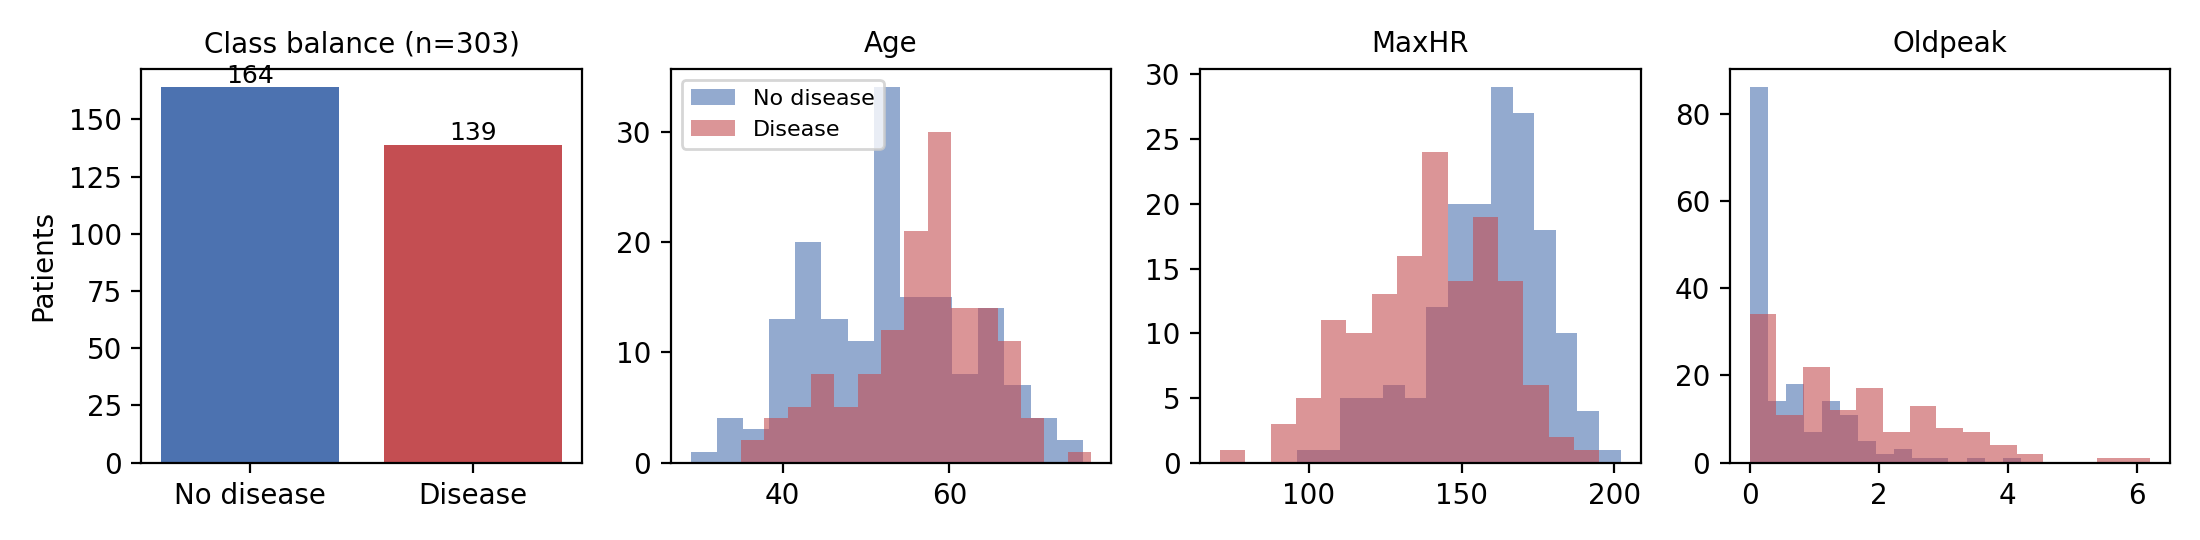

In [2]:
a = json.load(open(R / "data_audit.json"))
for k in ["source_file", "rows", "n_features", "class_counts", "original_severity_counts_num_0_to_4",
          "native_missing_cells_by_feature", "native_missing_cells_total", "rows_with_any_native_missing",
          "zero_cholesterol_rows", "zero_restingbp_rows"]:
    print(f"{k:40s} {a[k]}")
show_fig("fig1_data_audit.png", 900)

## 2. Performance as data go missing (matched scenario: training and test data both incomplete)
Mean ± SD over 15 runs (5-fold stratified CV × 3 repeats). Missing level = % of feature cells removed at random, on top of the 6 original missing cells.

Balanced accuracy


L,0%,10%,20%,30%,40%,50%
Model,,,,,,
LR + knn,0.842 ± 0.056,0.837 ± 0.051,0.829 ± 0.057,0.796 ± 0.038,0.789 ± 0.046,0.766 ± 0.046
LR + median,0.844 ± 0.054,0.828 ± 0.038,0.827 ± 0.052,0.788 ± 0.036,0.773 ± 0.056,0.771 ± 0.061
Majority,0.5 ± 0.0,0.5 ± 0.0,0.5 ± 0.0,0.5 ± 0.0,0.5 ± 0.0,0.5 ± 0.0
RF + knn,0.831 ± 0.056,0.814 ± 0.057,0.815 ± 0.06,0.801 ± 0.045,0.78 ± 0.044,0.764 ± 0.049
RF + median,0.83 ± 0.052,0.805 ± 0.047,0.809 ± 0.041,0.768 ± 0.048,0.771 ± 0.057,0.759 ± 0.056


ROC-AUC


L,0%,10%,20%,30%,40%,50%
Model,,,,,,
LR + knn,0.916 ± 0.035,0.908 ± 0.036,0.907 ± 0.037,0.879 ± 0.034,0.866 ± 0.035,0.853 ± 0.047
LR + median,0.916 ± 0.034,0.903 ± 0.035,0.901 ± 0.039,0.867 ± 0.031,0.862 ± 0.041,0.857 ± 0.049
Majority,0.5 ± 0.0,0.5 ± 0.0,0.5 ± 0.0,0.5 ± 0.0,0.5 ± 0.0,0.5 ± 0.0
RF + knn,0.915 ± 0.038,0.905 ± 0.041,0.897 ± 0.038,0.872 ± 0.035,0.858 ± 0.035,0.842 ± 0.048
RF + median,0.913 ± 0.038,0.897 ± 0.038,0.893 ± 0.039,0.854 ± 0.043,0.843 ± 0.053,0.836 ± 0.053


Recall (disease)


L,0%,10%,20%,30%,40%,50%
Model,,,,,,
LR + knn,0.796 ± 0.096,0.792 ± 0.079,0.789 ± 0.1,0.746 ± 0.081,0.751 ± 0.084,0.718 ± 0.133
LR + median,0.796 ± 0.09,0.78 ± 0.069,0.787 ± 0.099,0.724 ± 0.089,0.72 ± 0.09,0.71 ± 0.117
Majority,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0
RF + knn,0.784 ± 0.101,0.76 ± 0.096,0.768 ± 0.097,0.746 ± 0.093,0.753 ± 0.07,0.722 ± 0.124
RF + median,0.777 ± 0.093,0.755 ± 0.08,0.782 ± 0.084,0.712 ± 0.099,0.744 ± 0.096,0.739 ± 0.104


Brier score (lower is better)


L,0%,10%,20%,30%,40%,50%
Model,,,,,,
LR + knn,0.115 ± 0.023,0.122 ± 0.024,0.124 ± 0.024,0.14 ± 0.019,0.148 ± 0.022,0.157 ± 0.025
LR + median,0.116 ± 0.022,0.124 ± 0.021,0.127 ± 0.023,0.148 ± 0.017,0.15 ± 0.022,0.156 ± 0.026
Majority,0.248 ± 0.0,0.248 ± 0.0,0.248 ± 0.0,0.248 ± 0.0,0.248 ± 0.0,0.248 ± 0.0
RF + knn,0.124 ± 0.021,0.128 ± 0.02,0.132 ± 0.021,0.147 ± 0.016,0.155 ± 0.018,0.165 ± 0.022
RF + median,0.124 ± 0.021,0.135 ± 0.018,0.138 ± 0.019,0.159 ± 0.019,0.164 ± 0.023,0.169 ± 0.022


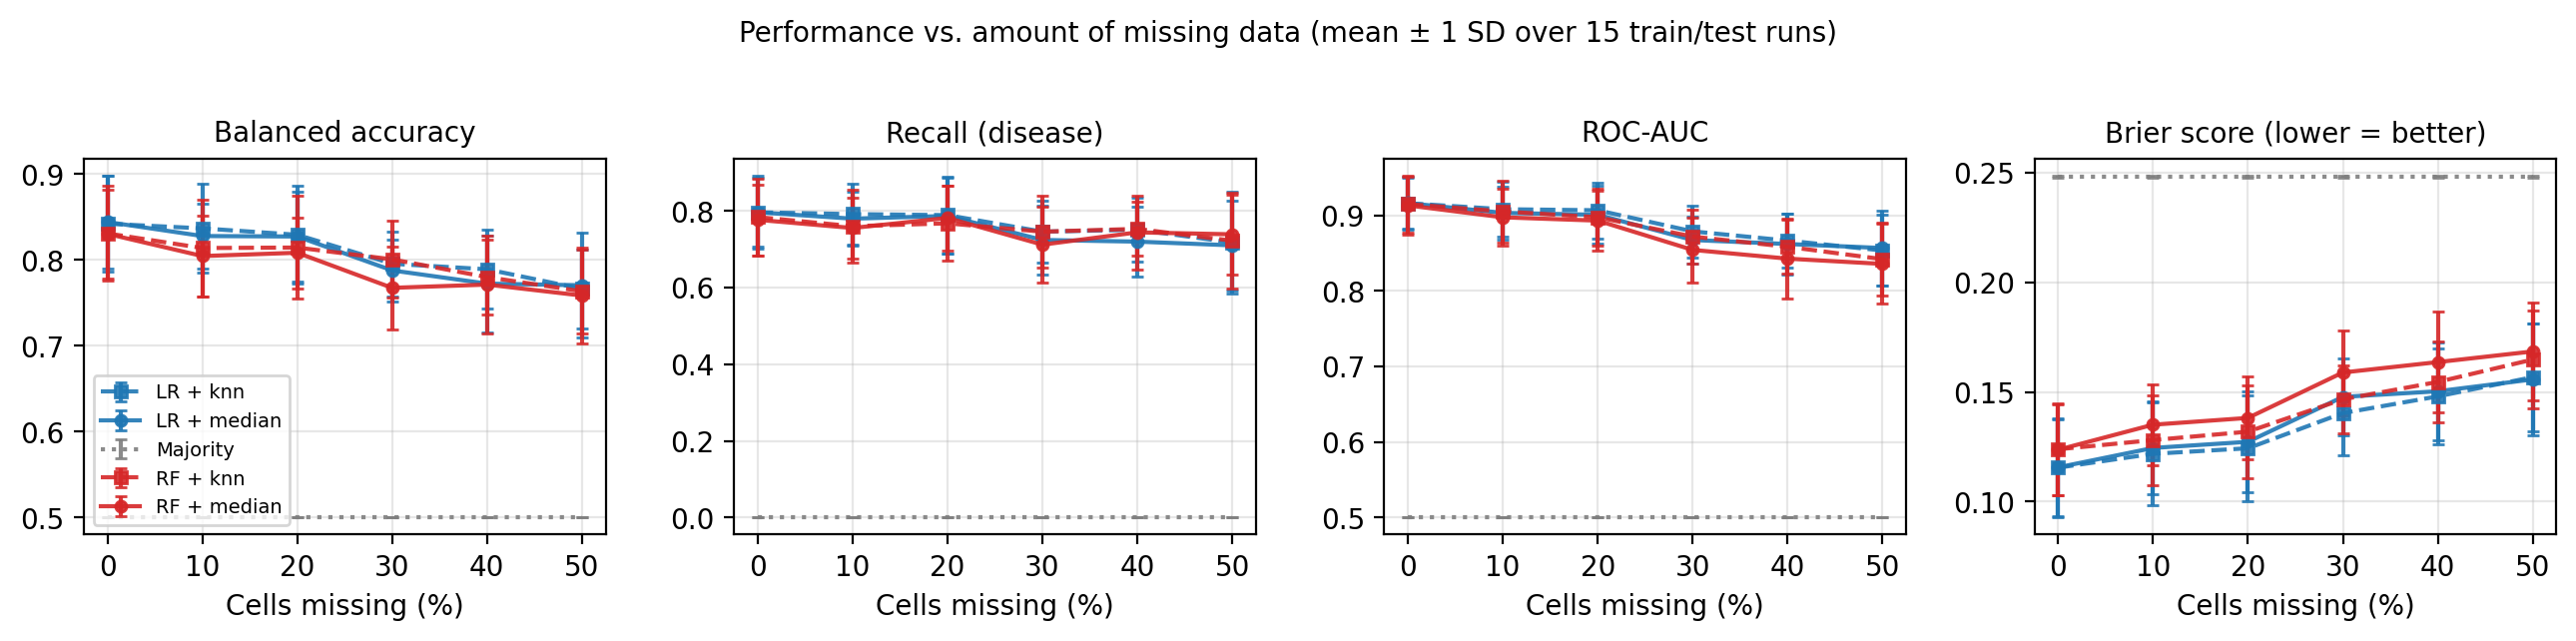

In [3]:
perf = pd.read_csv(R / "summary_performance_matched.csv")
perf["Model"] = perf.model + np.where(perf.imputer == "-", "", " + " + perf.imputer)
for metric, name in [("bal_acc", "Balanced accuracy"), ("auc", "ROC-AUC"), ("recall", "Recall (disease)"), ("brier", "Brier score (lower is better)")]:
    t = perf.assign(v=ms(perf, metric), L=perf.level.map(pct)).pivot(index="Model", columns="L", values="v")
    t = t[[pct(l) for l in sorted(perf.level.unique())]]
    print(name); display(t)
show_fig("fig2_performance_vs_missing.png", 1000)

## 3. Random Forest vs Logistic Regression (paired differences, same folds and masks)

In [4]:
p = pd.read_csv(R / "summary_paired_RF_vs_LR.csv")
p["level"] = p.level.map(pct)
display(p[["imputer", "level", "bal_acc_RF_minus_LR_mean", "bal_acc_RF_minus_LR_sd", "bal_acc_share_folds_RF_better",
           "auc_RF_minus_LR_mean", "brier_RF_minus_LR_mean"]].round(3).rename(columns={
    "bal_acc_RF_minus_LR_mean": "bal.acc RF-LR (mean)", "bal_acc_RF_minus_LR_sd": "(SD)", "bal_acc_share_folds_RF_better": "share of runs RF better",
    "auc_RF_minus_LR_mean": "AUC RF-LR", "brier_RF_minus_LR_mean": "Brier RF-LR"}))

,imputer,level,bal.acc RF-LR (mean),(SD),share of runs RF better,AUC RF-LR,Brier RF-LR
0,knn,0%,-0.011,0.031,0.267,-0.001,0.008
1,knn,10%,-0.023,0.034,0.200,-0.003,0.006
2,knn,20%,-0.015,0.038,0.267,-0.009,0.008
3,knn,30%,0.005,0.031,0.400,-0.007,0.006
4,knn,40%,-0.009,0.032,0.333,-0.008,0.007
5,knn,50%,-0.003,0.026,0.467,-0.011,0.008
6,median,0%,-0.014,0.027,0.267,-0.003,0.008
7,median,10%,-0.023,0.034,0.267,-0.006,0.011
8,median,20%,-0.019,0.039,0.333,-0.008,0.011
9,median,30%,-0.020,0.033,0.133,-0.013,0.011


## 4. Selective prediction (abstain on uncertain cases; threshold chosen on validation data for ~80% coverage)
*Selective risk* = error among answered cases. *Risk w/o abstaining* = error of the same model if no case is skipped.

,Model,Missing,Coverage,Selective risk,Risk w/o abstaining,Risk reduction
0,LR + knn,0%,0.767 ± 0.082,0.106 ± 0.05,0.157 ± 0.055,0.051
1,LR + knn,30%,0.8 ± 0.065,0.149 ± 0.054,0.199 ± 0.047,0.050
2,LR + knn,50%,0.785 ± 0.082,0.155 ± 0.057,0.219 ± 0.061,0.064
3,LR + median,0%,0.773 ± 0.081,0.112 ± 0.051,0.158 ± 0.053,0.047
4,LR + median,30%,0.778 ± 0.077,0.157 ± 0.06,0.207 ± 0.048,0.050
5,LR + median,50%,0.791 ± 0.065,0.173 ± 0.068,0.231 ± 0.059,0.058
6,RF + knn,0%,0.782 ± 0.093,0.112 ± 0.035,0.165 ± 0.054,0.053
7,RF + knn,30%,0.771 ± 0.057,0.153 ± 0.038,0.212 ± 0.038,0.059
8,RF + knn,50%,0.771 ± 0.084,0.18 ± 0.064,0.244 ± 0.048,0.064
9,RF + median,0%,0.788 ± 0.09,0.113 ± 0.039,0.166 ± 0.051,0.053


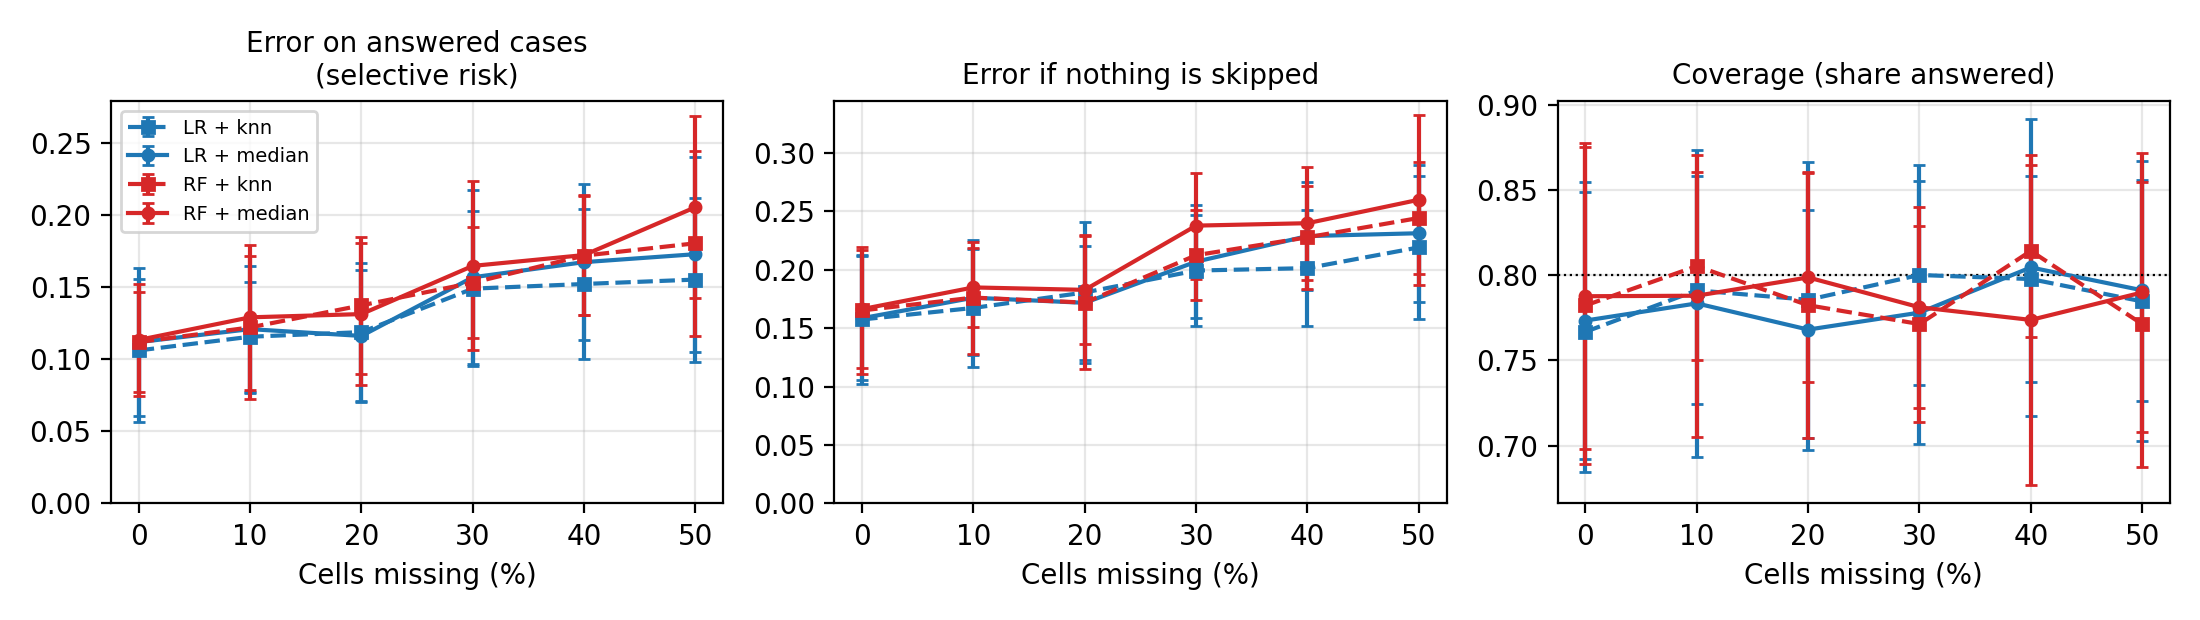

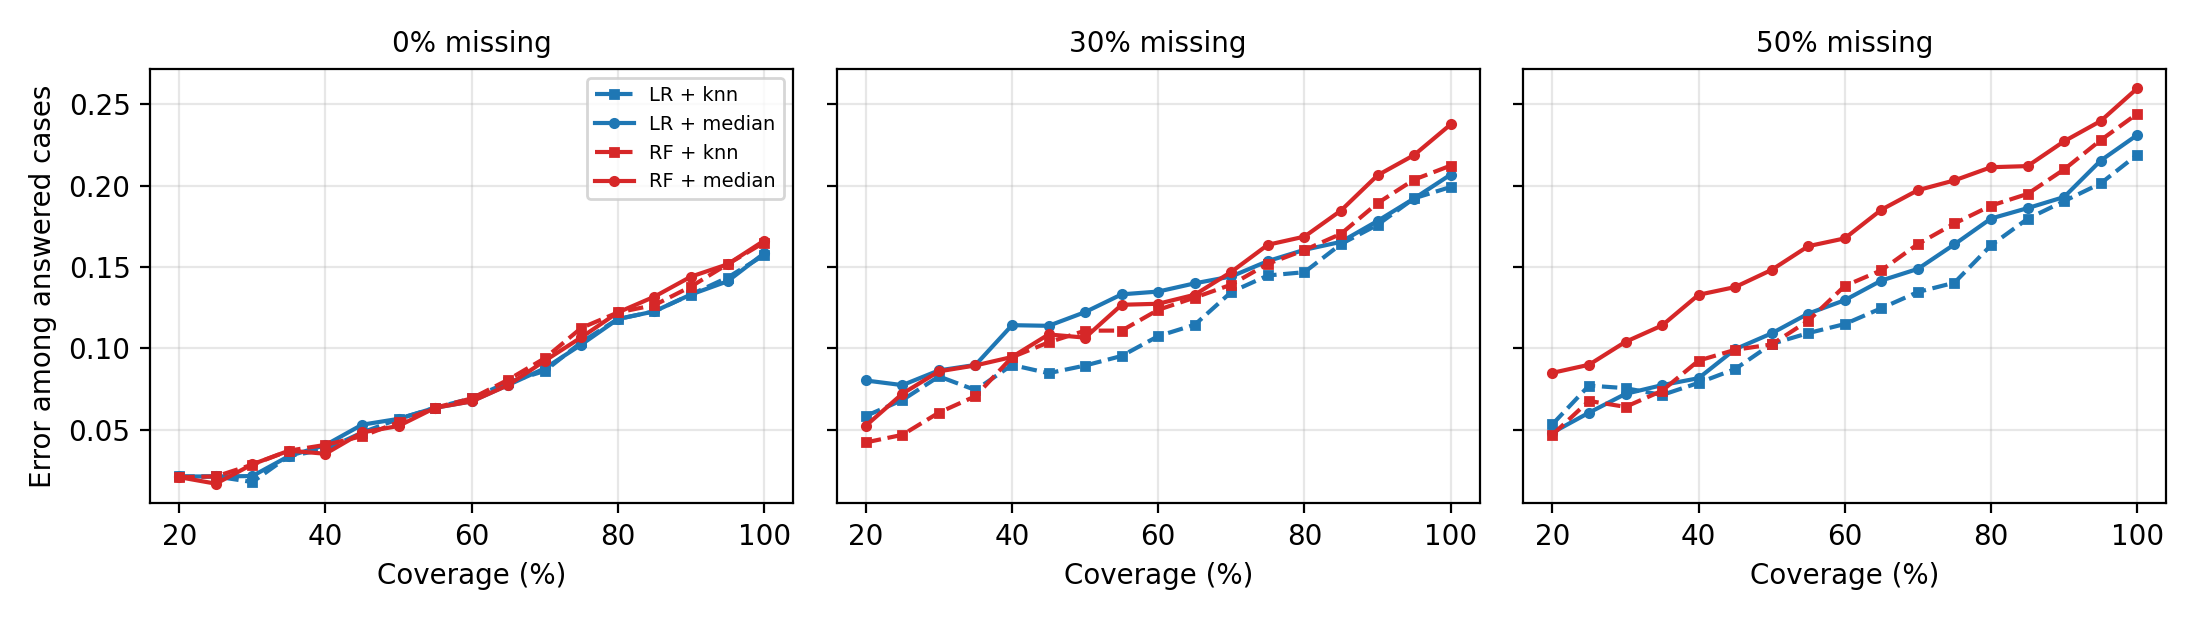

In [5]:
s = pd.read_csv(R / "summary_selective.csv")
m = s[(s.scenario == "matched") & s.level.isin([0.0, 0.3, 0.5])].copy()
m["Model"] = m.model + " + " + m.imputer; m["Missing"] = m.level.map(pct)
m["Coverage"] = ms(m, "coverage"); m["Selective risk"] = ms(m, "sel_risk"); m["Risk w/o abstaining"] = ms(m, "risk_all")
m["Risk reduction"] = m.risk_reduction.round(3)
display(m[["Model", "Missing", "Coverage", "Selective risk", "Risk w/o abstaining", "Risk reduction"]].sort_values(["Model", "Missing"]).reset_index(drop=True))
show_fig("fig3_selective_vs_missing.png", 1000)
show_fig("fig4_risk_coverage.png", 1000)

## 5. Graduate depth analysis — failure-mode audit
If training, tuning and the confidence threshold use **clean** data, does the system still behave as planned when incoming data are incomplete?
Paired differences (clean-threshold scenario minus matched scenario; same test masks).

,model,imputer,Missing,coverage change (mean),(SD),share of runs coverage lower,error change at equal 80% coverage,(SD)
0,LR,knn,30%,-0.025,0.086,0.667,0.012,0.028
1,LR,knn,50%,-0.014,0.079,0.467,0.008,0.029
2,LR,median,30%,-0.071,0.099,0.800,0.010,0.026
3,LR,median,50%,-0.120,0.113,0.933,0.030,0.035
4,RF,knn,30%,0.041,0.057,0.267,-0.001,0.032
5,RF,knn,50%,0.070,0.075,0.067,-0.015,0.053
6,RF,median,30%,-0.022,0.076,0.467,0.016,0.038
7,RF,median,50%,-0.055,0.143,0.667,0.038,0.050


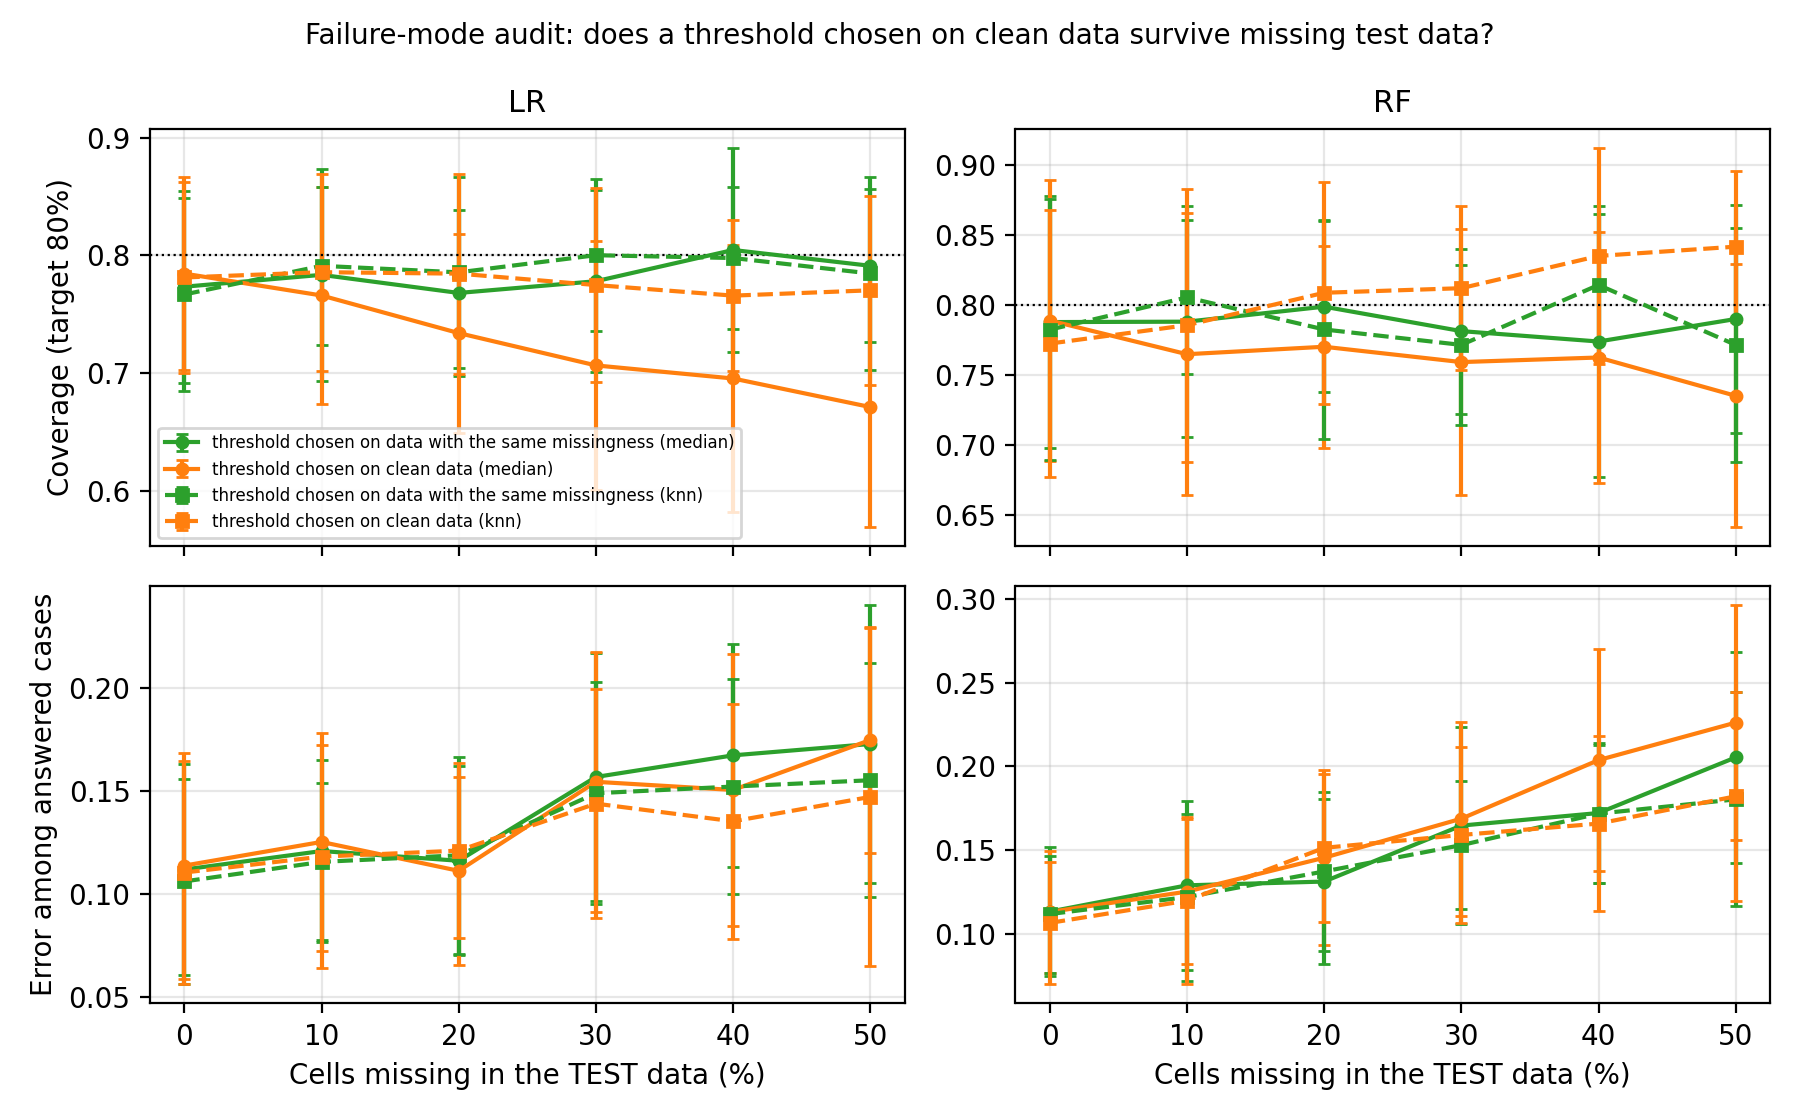

In [6]:
j = pd.read_csv(R / "summary_failure_mode_paired.csv")
j = j[j.level.isin([0.3, 0.5])].copy(); j["Missing"] = j.level.map(pct)
display(j[["model", "imputer", "Missing", "cov_diff_mean", "cov_diff_sd", "share_folds_coverage_lower", "rc80_diff_mean", "rc80_diff_sd"]].round(3).rename(columns={
    "cov_diff_mean": "coverage change (mean)", "cov_diff_sd": "(SD)", "share_folds_coverage_lower": "share of runs coverage lower",
    "rc80_diff_mean": "error change at equal 80% coverage", "rc80_diff_sd": "(SD)"}).reset_index(drop=True))
show_fig("fig5_failure_mode_audit.png", 900)

## 6. Probability reliability and error analysis

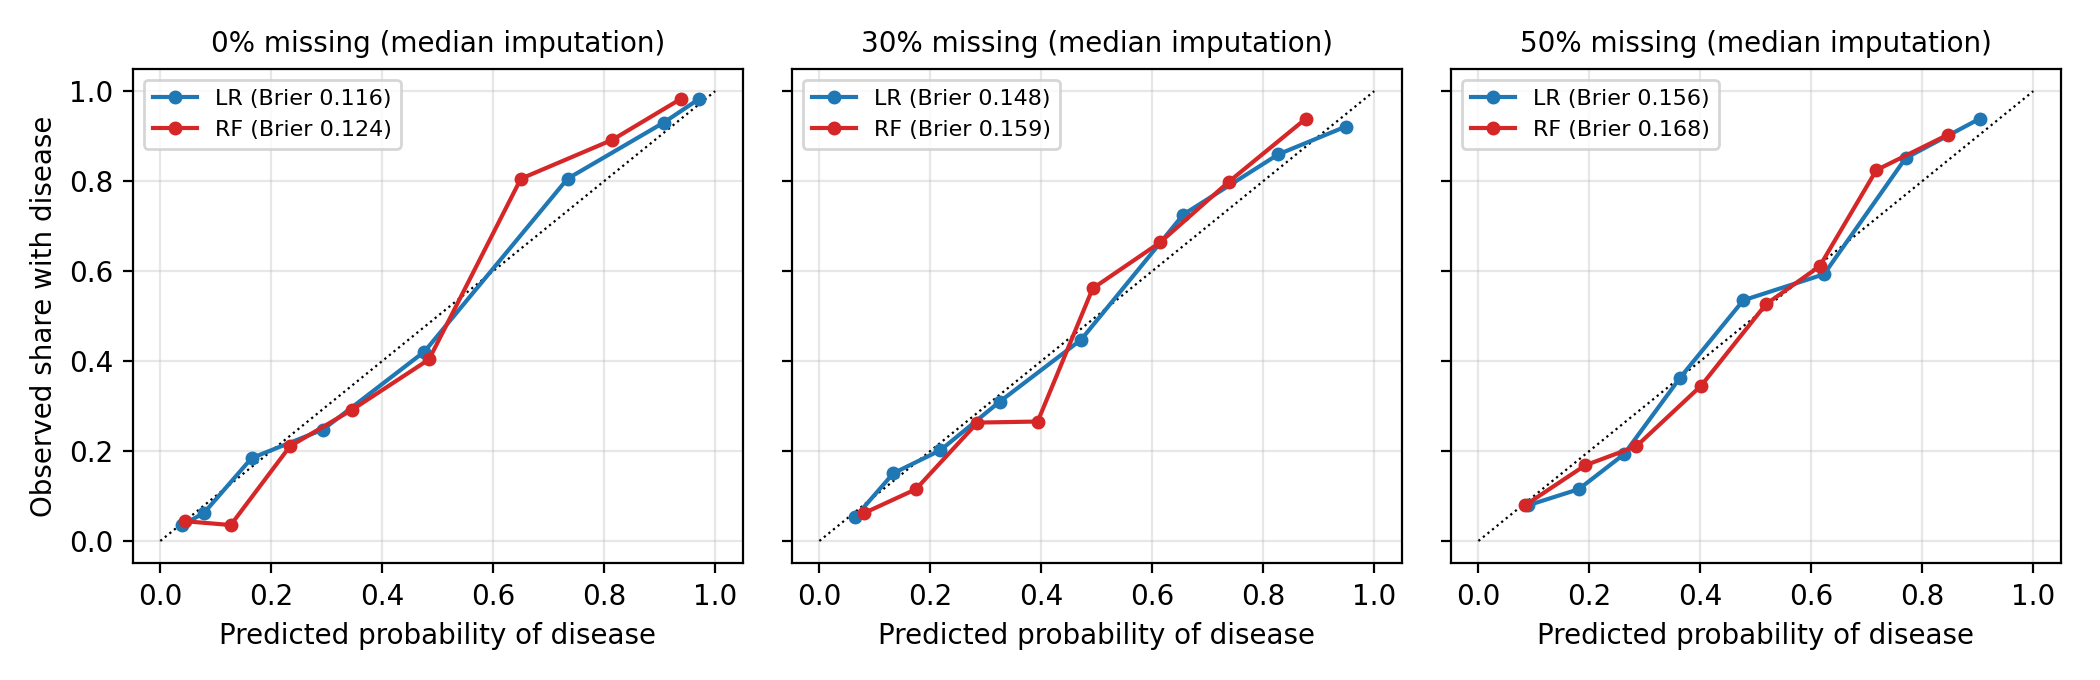

,Model,Missing,missed disease (FN rate),false alarm (FP rate),FN share of errors,skipped | wrong,skipped | correct
0,LR + median,0%,0.204,0.120,0.590,0.444,0.186
1,LR + median,30%,0.276,0.148,0.612,0.399,0.176
2,LR + median,50%,0.295,0.177,0.586,0.400,0.152
3,RF + median,0%,0.211,0.128,0.583,0.457,0.164
4,RF + median,30%,0.285,0.197,0.551,0.454,0.146
5,RF + median,50%,0.293,0.232,0.517,0.377,0.152


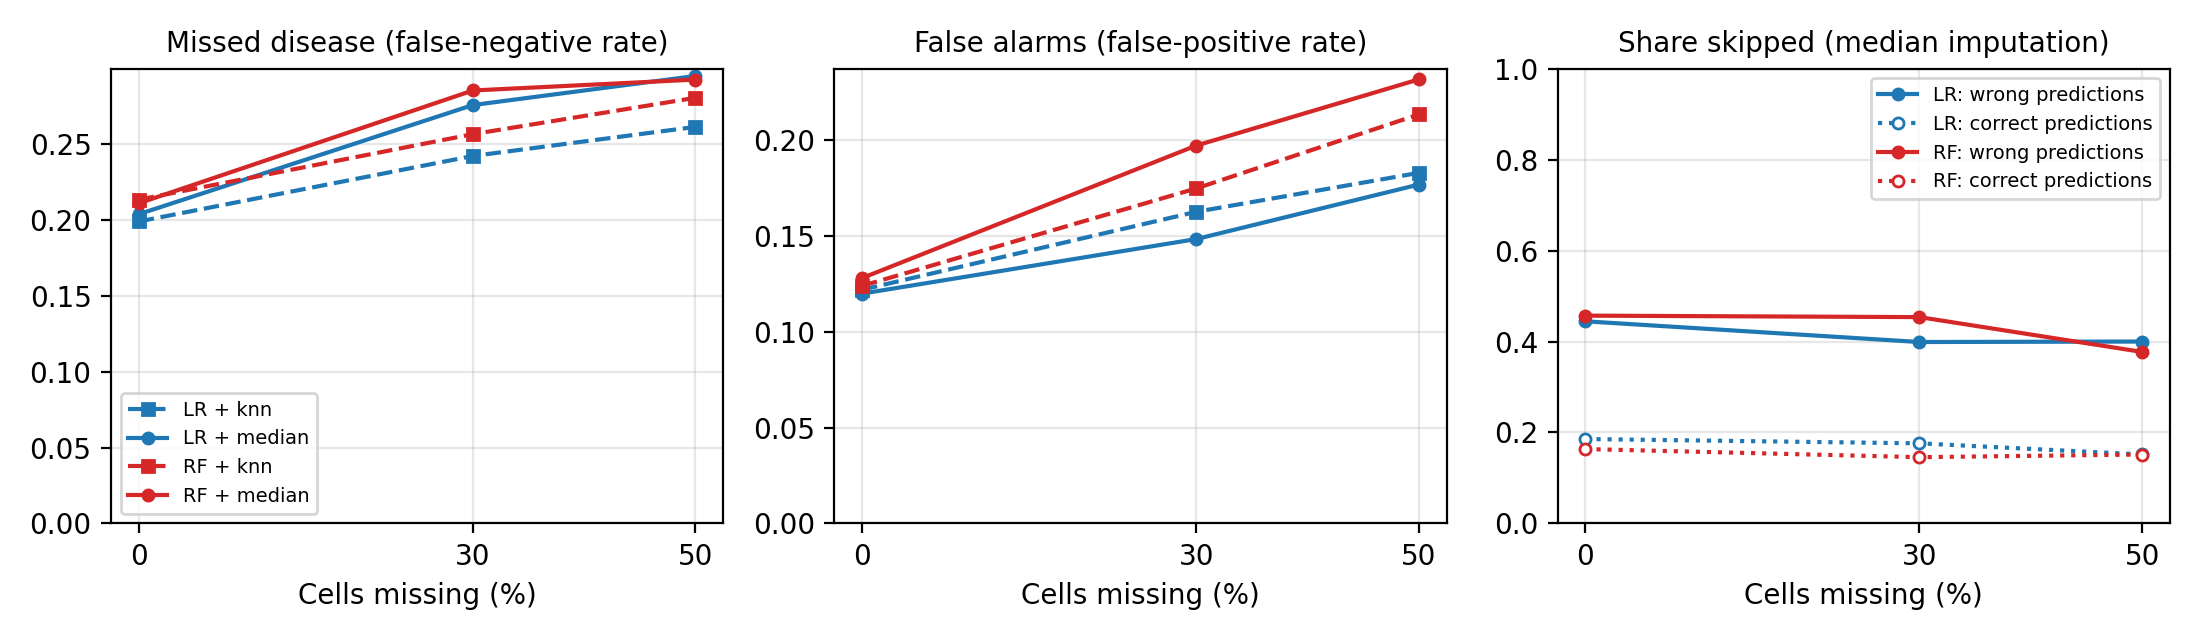

Patients misclassified in all 3 of their test appearances (median imputation):


,model,Missing,patients_always_wrong,share_of_patients,share_abstained_among_always_wrong,share_abstained_among_never_wrong
0,LR,0%,33.0,0.109,0.242,0.139
1,LR,30%,26.0,0.086,0.218,0.115
2,LR,50%,23.0,0.076,0.275,0.119
3,RF,0%,37.0,0.122,0.306,0.130
4,RF,30%,31.0,0.102,0.269,0.090
5,RF,50%,21.0,0.069,0.286,0.124


In [7]:
show_fig("fig6_reliability.png", 1000)
e = pd.read_csv(R / "error_analysis_types.csv")
e = e[(e.imputer == "median")].copy(); e["Missing"] = e.level.map(pct); e["Model"] = e.model + " + median"
display(e[["Model", "Missing", "miss_rate_FN", "false_alarm_rate_FP", "share_of_errors_that_are_FN", "abstain_rate_on_wrong", "abstain_rate_on_correct"]].round(3).rename(columns={
    "miss_rate_FN": "missed disease (FN rate)", "false_alarm_rate_FP": "false alarm (FP rate)", "share_of_errors_that_are_FN": "FN share of errors",
    "abstain_rate_on_wrong": "skipped | wrong", "abstain_rate_on_correct": "skipped | correct"}).reset_index(drop=True))
show_fig("fig7_error_analysis.png", 1000)
pc = pd.read_csv(R / "error_analysis_persistent_counts.csv"); pc = pc[pc.imputer == "median"].copy(); pc["Missing"] = pc.level.map(pct)
print("Patients misclassified in all 3 of their test appearances (median imputation):")
display(pc[["model", "Missing", "patients_always_wrong", "share_of_patients", "share_abstained_among_always_wrong", "share_abstained_among_never_wrong"]].round(3).reset_index(drop=True))

## 7. Written summary of the results and limitations
(Displayed from `results/RESULTS_SUMMARY.md`.)

In [8]:
display(Markdown((R / "RESULTS_SUMMARY.md").read_text(encoding="utf-8")))

# What the results show (read together with `results_tables.md` and `error_analysis.md`)

Data: Cleveland subset, 303 patients, 13 features (6 original missing cells). All numbers are means over 15 runs
(5-fold stratified CV × 3 repeats); "SD" is the spread across those runs. The 15 runs share training data, so SDs describe
variability, they are **not** independent-sample confidence intervals, and no significance tests were run.
"X% missing" = X% of the feature cells removed at random *in addition to* the 6 original missing cells.
Hyper-parameters were tuned by inner cross-validation inside every training fold (Logistic Regression chose C = 0.1 in 406 of 420
tuning runs; Random Forest spread over min_samples_leaf = 3 (193), 1 (141), 5 (81), 10 (5)).

## 1. Missing data lowers reliability gradually, and the models stay well above the baseline
* Majority-class baseline: balanced accuracy 0.500, recall 0.000 (it always predicts "no disease"), ROC-AUC 0.500, Brier 0.248.
* Logistic Regression at 0% missing: balanced accuracy 0.844 ± 0.054, ROC-AUC 0.916 ± 0.034, Brier 0.116 (median imputation).
  At 50% missing: balanced accuracy 0.771 (median) / 0.766 (KNN), ROC-AUC 0.857 / 0.853, Brier 0.156 / 0.157.
* Random Forest: balanced accuracy 0.830 → 0.759 (median) / 0.831 → 0.764 (KNN); ROC-AUC 0.913 → 0.836 / 0.915 → 0.842.
* Recall for disease falls from about 0.78–0.80 to about 0.71–0.74 at 50% missing.
* The decline is gradual, with no collapse in the 0–50% range tested (for Logistic Regression the largest single step is 20% → 30%).

## 2. Random Forest did not beat Logistic Regression
Paired RF − LR difference in balanced accuracy (same folds, same masks) is between −0.023 and +0.005 at every level and imputer
(fold-to-fold SD 0.025–0.039); RF is better in only 13–47% of runs (`summary_paired_RF_vs_LR.csv`). RF is slightly worse on average in ROC-AUC
(by 0.001–0.021) and in Brier score (by 0.006–0.013) in all 12 level/imputer combinations, but these gaps are small relative to the noise.
So there is no evidence that the more flexible model helps here.

## 3. Median vs. KNN imputation: small differences
KNN was nominally ahead in balanced accuracy in 10 of the 12 model/level comparisons, by 0.001–0.033 (largest: RF at 30%: 0.801 vs 0.768),
always smaller than the run-to-run SD (about 0.04–0.06). At 0% injected missingness the two imputers still differ slightly (identical in 63% of runs,
mean |difference| 0.0065) because 6 cells are genuinely missing. The data do not establish that one imputer is better.

## 4. Selective prediction reduces errors, and the benefit holds across missing-data levels
* At ~80% target coverage the error among answered cases is lower than the error without abstaining in all 24 model/imputer/level settings.
  Examples (0% missing): LR + median 0.158 → 0.112 at 0.773 mean test coverage; RF + median 0.166 → 0.113 at 0.788.
  (50% missing): LR + median 0.231 → 0.173; LR + KNN 0.219 → 0.155; RF + median 0.260 → 0.205; RF + KNN 0.244 → 0.180.
* The mean reduction is 0.034–0.073 and stays roughly constant (about 0.05–0.06) from 0% to 50% missing; it is positive in 73–100% of the 15 runs.
* Abstention does not fully compensate for missing data: at 50% missing it brings LR + KNN to about the error of answering everyone on complete data
  (0.155 vs 0.157, while skipping ~21% of patients), but the other three configurations stay above that level (0.173–0.205 vs 0.158–0.166).
* Realised test coverage averages 0.767–0.814 around the 0.80 target (mean validation coverage 0.804); individual test folds (~61 patients) vary by an SD of 0.05–0.10.
* The majority-class baseline is not shown for selective prediction (its confidence is constant).

## 5. Graduate depth analysis — failure-mode audit
Question: if training, tuning and the confidence threshold use clean data, does the system still behave as planned when incoming data are incomplete?
(Test masks are identical to the matched scenario, so differences are paired.)
* **Median imputation: coverage drops below the planned 80%.** LR coverage falls from 0.785 (0% missing) to 0.671 at 50%; the paired difference to the matched
  threshold is −0.120 ± 0.113 at 50% (lower in 14 of 15 runs). RF: 0.789 → 0.735 (−0.055 ± 0.143, lower in 10 of 15 runs).
* **The direction depends on model and imputer.** With KNN imputation LR shows no consistent change (−0.014 at 50%), while RF + KNN *over*-answers:
  coverage 0.842 at 50% (+0.070 ± 0.075; lower in only 1 of 15 runs).
* **Error at equal 80% coverage:** for median imputation the clean-trained models are somewhat worse at 50% (LR +0.030, RF +0.038; SD 0.035–0.050; worse in 73% of runs);
  for KNN the difference is within noise (+0.008 LR, −0.015 RF).
  Error without abstaining at 50% missing tells a similar story: clean training is worse for median imputation (LR 0.260 vs 0.231, RF 0.290 vs 0.260) but not worse with KNN
  (LR 0.209 vs 0.219, RF 0.220 vs 0.244; differences within noise).
* So a threshold set on clean data is not reliable under missing data: with median imputation the system silently answers fewer patients than planned and is a little less accurate, and
  with RF + KNN it answers more than planned.
* Possible explanation (hypothesis, not tested): median-imputed values pull predicted probabilities toward the middle, lowering confidence.

## 6. Probability reliability (Fig. 6, pooled test predictions, median imputation)
Brier score rises with missingness (LR 0.116 → 0.148 → 0.156 at 0/30/50%; RF 0.124 → 0.159 → 0.168). See Fig. 6 for the reliability curves; with 303 patients the bins are noisy,
so treat them as descriptive.

## 7. Error analysis — representative errors (Fig. 7, `error_analysis.md`)
Pooled over the 15 runs, matched scenario, selective models (trained on 75% of each training fold).
* **Most errors are missed disease, and they increase with missing data.** For LR + median the false-negative rate (diseased patients predicted healthy) is 0.204 at 0%, 0.276 at 30% and 0.295 at 50%;
  the false-positive rate is 0.120, 0.148 and 0.177. Missed disease makes up 52–61% of all errors across the four configurations.
* **Abstention preferentially skips wrong predictions, but misses most of them.** LR + median at 0% missing skips 44% of its wrong predictions versus 19% of its correct ones
  (RF: 46% vs 16%); at 50% the figures are 40% vs 15% (RF: 38% vs 15%). Still, more than half of the wrong predictions are answered. Error rate among skipped cases is 0.31 (0%) to 0.44 (50%)
  for LR + median, against 0.11–0.18 among answered cases.
* **Some patients are wrong every time.** At 0% missing, 33 patients (10.9%) are misclassified in all 3 of their test appearances by LR + median (RF + median: 37, 12.2%);
  at 50% missing 23 (7.6%) and 21 (6.9%). About 64% of the always-wrong patients truly have the disease. They are skipped in only 24% (LR) / 31% (RF) of their appearances,
  versus 14% / 13% for patients that are never wrong: the persistent mistakes are mostly **confident** mistakes that abstention does not catch.
* **What the confident mistakes look like (LR + median, 0% missing, 8 most confident).** Five are patients with disease who look low-risk on every recorded feature (no exercise angina,
  no coloured vessels, normal thal, Oldpeak 0; predicted probability of disease 0.04–0.14 for all five); three are healthy patients with a reversible thal defect and 1–3 coloured vessels
  (predicted probability 0.90–0.94). None of the eight was ever skipped.
* **By group (descriptive; groups are small).** Typical-angina patients (TA, n = 23) have the highest error rate (0.36 at 0% for LR + median, versus 0.12–0.16 for the other chest-pain types);
  male patients have a higher error rate than female patients (0.19 vs 0.10 at 0%; 0.26 vs 0.17 at 50%); error rates rise with age band at 0% (0.12 under 50, 0.17 for 50–59, 0.18 for 60+).
  With these sample sizes none of these differences should be over-interpreted.

## Limitations to state in the paper
* Small data set (303 patients, ~61 per test fold); results vary by fold. Repeated CV runs are not independent, and SDs are not confidence intervals.
* Missingness is simulated, completely at random (MCAR). Real clinical missingness is usually not random, so conclusions about MCAR need not transfer.
* Cleveland is a single-site sample with no external validation. The binary target merges disease severities (original labels 0–4).
* Only two model families and two imputers; tuning grids are small (4 settings each). Categorical variables are one-hot encoded with NaN propagated.
* The selective-prediction models are fitted on 75% of each training fold (25% held out to set the threshold), so they use less data than the models in Section 1.
* The error analysis pools repeated predictions of the same patients, and its group comparisons rest on small groups.
* Research exercise only, not a clinical decision tool.


## 8. Re-run everything from scratch (optional, about 20 minutes on one CPU core)
Uncomment and run. The leakage tests run first. The experiment step is resumable; finished folds are cached.

In [9]:
# !pip install -q -r requirements-experiment.txt
# !bash run_all.sh